In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt 
import seaborn as sns
import missingno as msno
import xgboost as xgb
from pathlib import Path
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)
import shap

In [2]:
results_df = pd.read_excel("../../data/processed/secondoneyeardata_results_data2.xlsx")
results_df

,Model,MAE,RMSE,R²
0,Linear Regression,6.838790,8.443221,0.223264
1,Decision Tree,9.477586,11.943221,-0.554176
2,Random Forest,7.962728,9.922012,-0.072647
3,Bagging,8.079931,10.102002,-0.111917
4,SVR,7.601904,9.459487,0.025027
5,XGBoost,7.645787,9.596059,-0.003329
6,Voting,7.314106,9.269881,0.063720


In [4]:
df = pd.read_excel("../../data/processed/second_one_year_mine_data_cleaned.xlsx")
df.columns = df.columns.str.strip()
df.head()

,Date,PM10,PM2.5,Temperature,Relative_humidity,RF-CUMULATIVE,Wind_speed,Road_width,Distance between the dust generation/source point and the haul road monitoring station,Production_ROM,Production_OB,Production_ROM+OB,Vehicle capacity,LOCATION,SEASON
0,2025-03-04,70.8,24.1,36.1,20.4,0.0,8.0,7,20,30000,75000,105000,2.5,Near_Office,Summer
1,2025-03-08,69.5,32.6,36.0,22.4,0.0,8.0,7,20,30000,75000,105000,2.5,Near_Office,Summer
2,2025-03-11,65.2,30.4,35.5,21.8,0.0,8.0,7,20,30000,75000,105000,2.5,Near_Office,Summer
3,2025-03-15,76.8,26.5,34.8,38.5,0.0,6.0,7,20,30000,75000,105000,2.5,Near_Office,Summer
4,2025-03-18,58.4,20.4,35.1,31.4,0.0,7.0,7,20,30000,75000,105000,2.5,Near_Office,Summer


In [5]:
features = [
        "Temperature",
        "Relative_humidity",
        "RF-CUMULATIVE",
        "Wind_speed",
        "Road_width",
        "Distance between the dust generation/source point and the haul road monitoring station",
        "Production_ROM",
        "Production_OB",
        "Production_ROM+OB",
        "Vehicle capacity",
        "LOCATION",
        "SEASON"
]

target_pm10 = "PM10"
target_pm25 = "PM2.5"

In [6]:
X = df[features]
y = df[target_pm10]

X = pd.get_dummies(X, drop_first=True)

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

C:\Users\DELL\AppData\Local\Temp\ipykernel_11844\3588624545.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


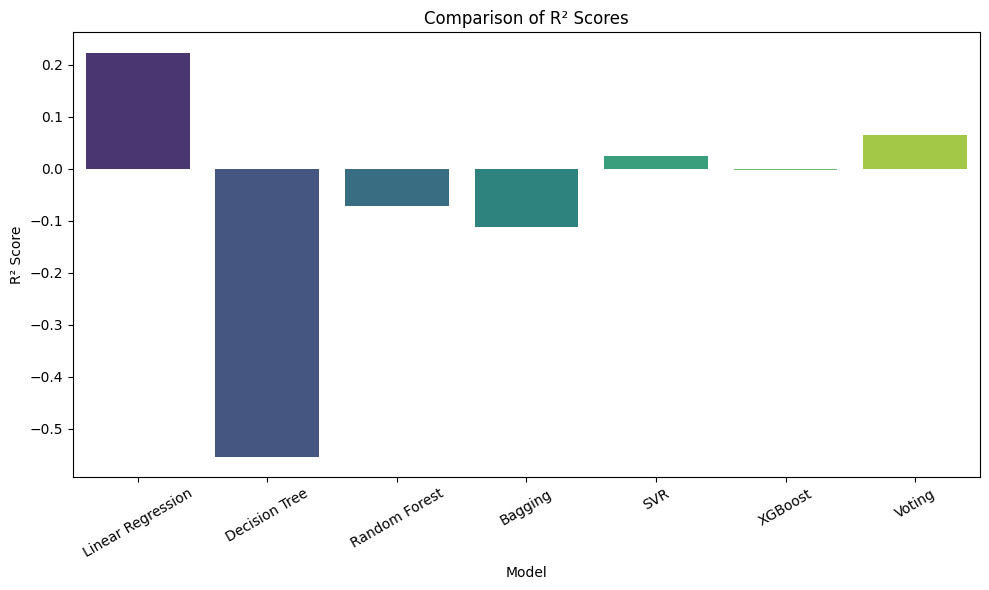

In [7]:
plt.figure(figsize=(10,6))

sns.barplot(
    data=results_df,
    x="Model",
    y="R²",
    palette="viridis"
)

plt.title("Comparison of R² Scores")

plt.xticks(rotation=30)

plt.ylabel("R² Score")

plt.tight_layout()

plt.show()

C:\Users\DELL\AppData\Local\Temp\ipykernel_11844\1072115408.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


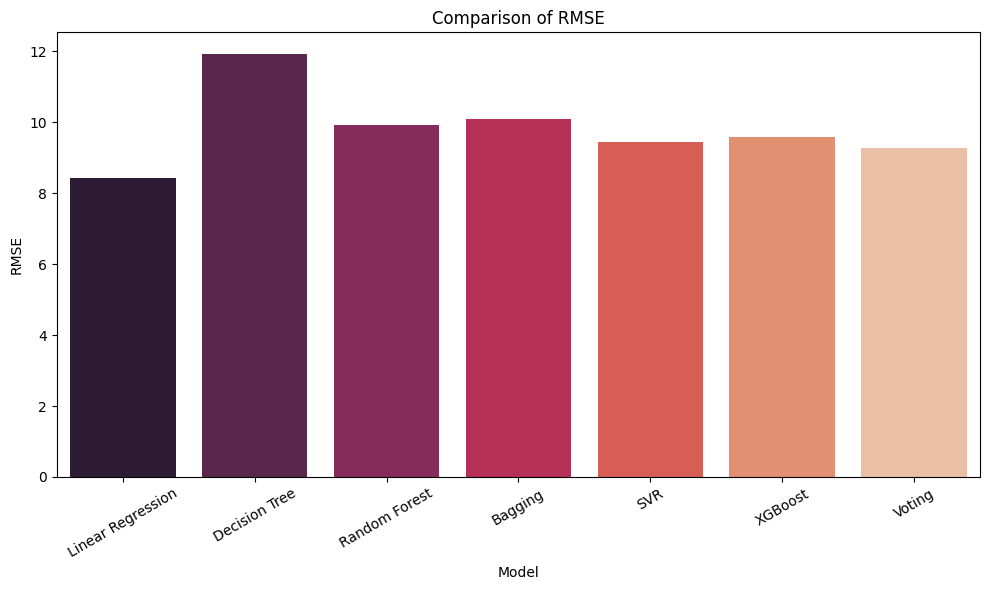

In [8]:
plt.figure(figsize=(10,6))

sns.barplot(
    data=results_df,
    x="Model",
    y="RMSE",
    palette="rocket"
)

plt.title("Comparison of RMSE")

plt.xticks(rotation=30)

plt.tight_layout()

plt.show()

C:\Users\DELL\AppData\Local\Temp\ipykernel_11844\1874031892.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


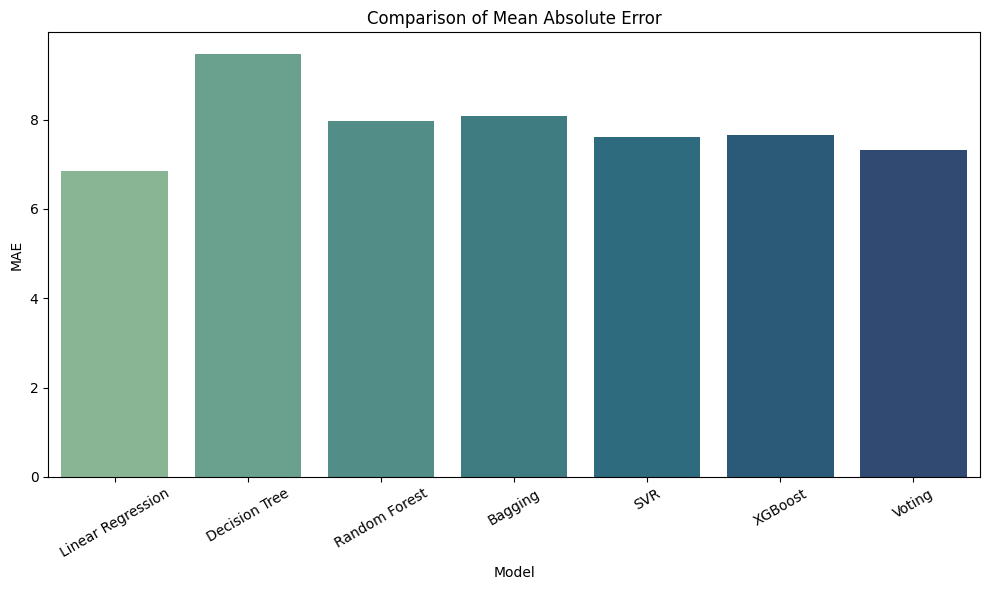

In [9]:
plt.figure(figsize=(10,6))

sns.barplot(
    data=results_df,
    x="Model",
    y="MAE",
    palette="crest"
)

plt.title("Comparison of Mean Absolute Error")

plt.xticks(rotation=30)

plt.tight_layout()

plt.show()

C:\Users\DELL\AppData\Local\Temp\ipykernel_11844\1874031892.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


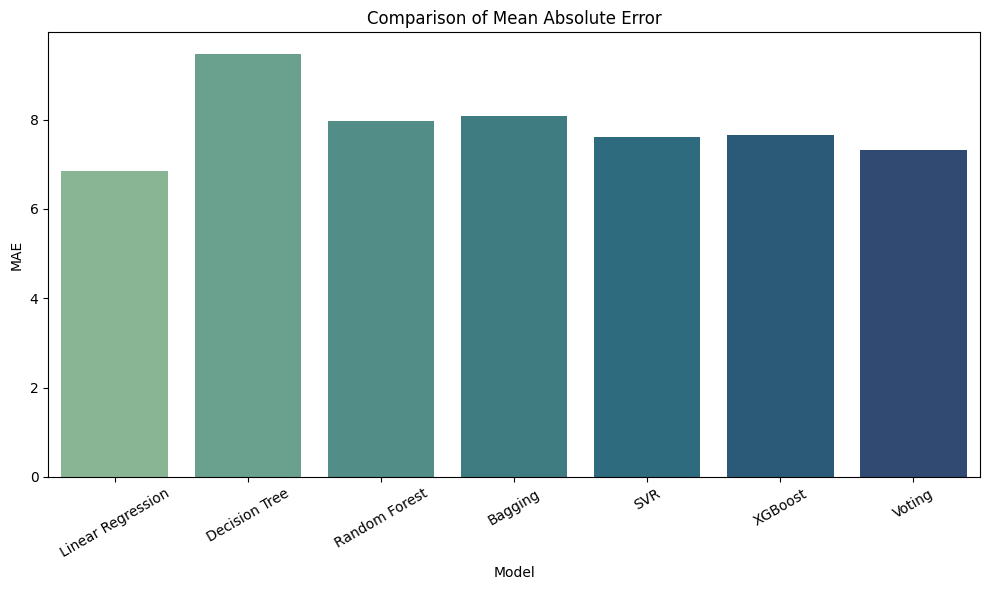

In [10]:
plt.figure(figsize=(10,6))

sns.barplot(
    data=results_df,
    x="Model",
    y="MAE",
    palette="crest"
)

plt.title("Comparison of Mean Absolute Error")

plt.xticks(rotation=30)

plt.tight_layout()

plt.show()

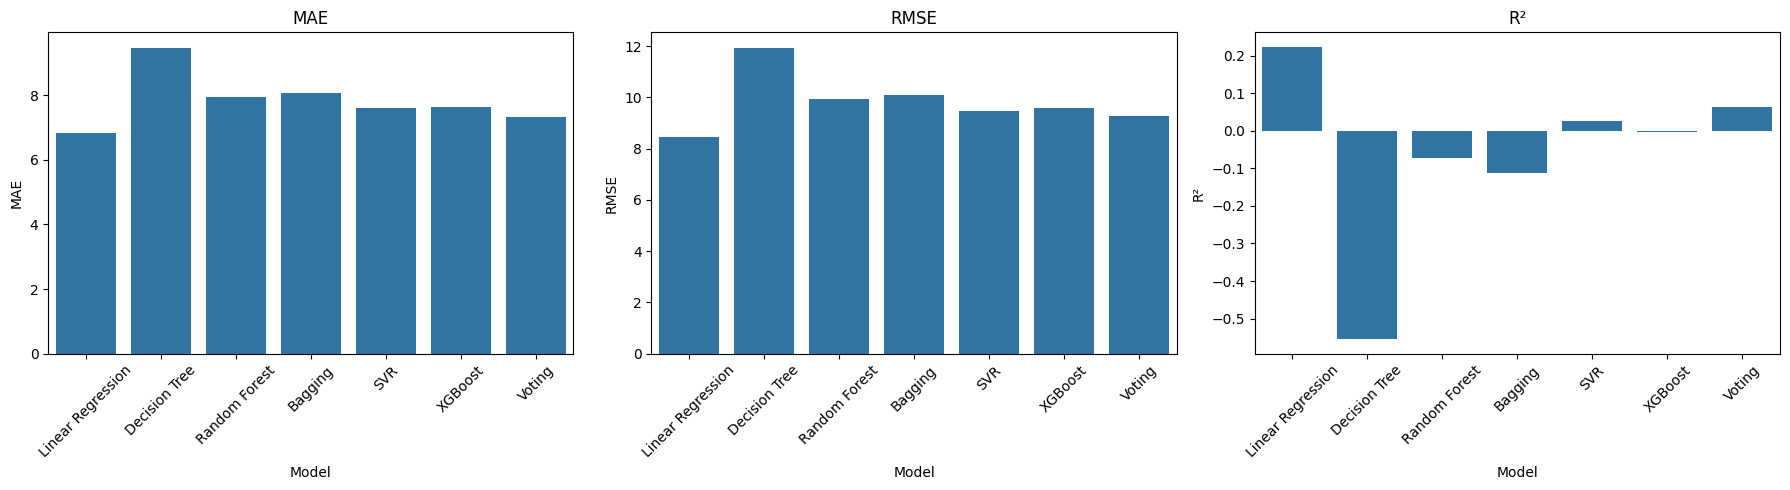

In [11]:
fig, axes = plt.subplots(1,3, figsize=(18,5))

sns.barplot(
    data=results_df,
    x="Model",
    y="MAE",
    ax=axes[0]
)

axes[0].set_title("MAE")

axes[0].tick_params(axis='x', rotation=45)

sns.barplot(
    data=results_df,
    x="Model",
    y="RMSE",
    ax=axes[1]
)

axes[1].set_title("RMSE")

axes[1].tick_params(axis='x', rotation=45)

sns.barplot(
    data=results_df,
    x="Model",
    y="R²",
    ax=axes[2]
)

axes[2].set_title("R²")

axes[2].tick_params(axis='x', rotation=45)

plt.tight_layout()

plt.show()

In [12]:
# XGBoost
xgb_model = xgb.XGBRegressor(
    objective="reg:squarederror",
    n_estimators=200,
    learning_rate=0.1,
    max_depth=4,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42
)
xgb_model.fit(X_train, y_train)
xgb_pred = xgb_model.predict(X_test)

In [13]:
mae = mean_absolute_error(y_test, xgb_pred)
rmse = np.sqrt(mean_squared_error(y_test, xgb_pred))
r2 = r2_score(y_test, xgb_pred)

print(mae)
print(rmse)
print(r2)

7.6457871338416785
9.59605894579972
-0.0033287017602574576


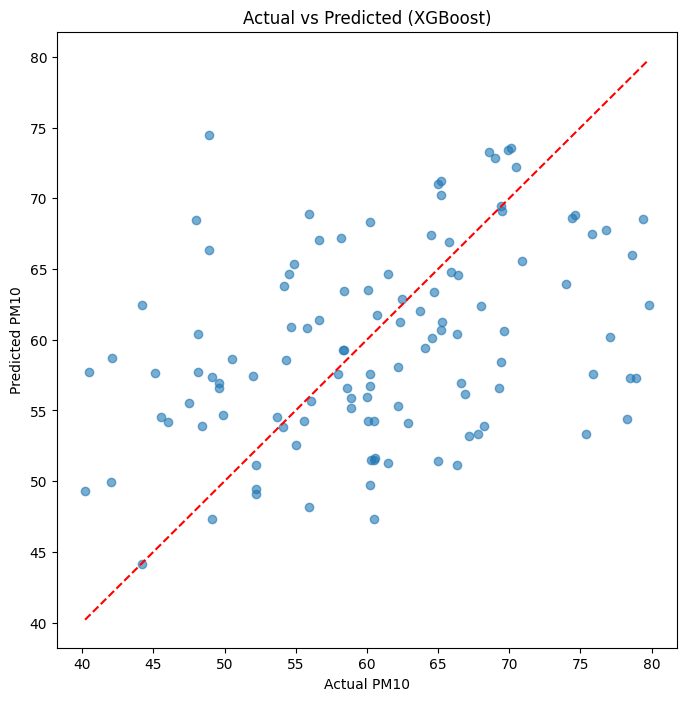

In [14]:
plt.figure(figsize=(8,8))

plt.scatter(
    y_test,
    xgb_pred,
    alpha=0.6
)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    'r--'
)

plt.xlabel("Actual PM10")

plt.ylabel("Predicted PM10")

plt.title("Actual vs Predicted (XGBoost)")

plt.show()

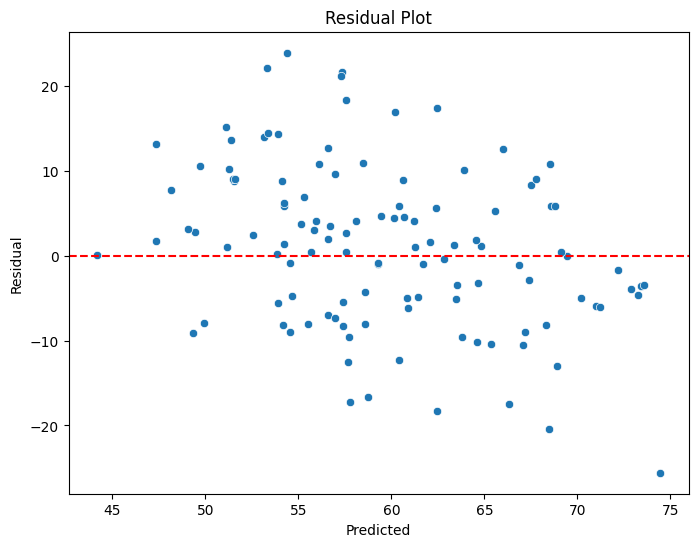

In [15]:
residuals = y_test - xgb_pred

plt.figure(figsize=(8,6))

sns.scatterplot(
    x=xgb_pred,
    y=residuals
)

plt.axhline(
    0,
    color='red',
    linestyle='--'
)

plt.xlabel("Predicted")

plt.ylabel("Residual")

plt.title("Residual Plot")

plt.show()

In [17]:
importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": xgb_model.feature_importances_
})

importance = importance.sort_values(
    by="Importance",
    ascending=False
)

display(importance)

,Feature,Importance
8,Production_ROM+OB,0.210887
17,SEASON_Winter,0.138360
7,Production_OB,0.129773
14,LOCATION_Working Area,0.080735
6,Production_ROM,0.078880
3,Wind_speed,0.055430
13,LOCATION_Weigh Bridge,0.052612
16,SEASON_Summer,0.039993
0,Temperature,0.035919
1,Relative_humidity,0.035674


C:\Users\DELL\AppData\Local\Temp\ipykernel_11844\3158664850.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


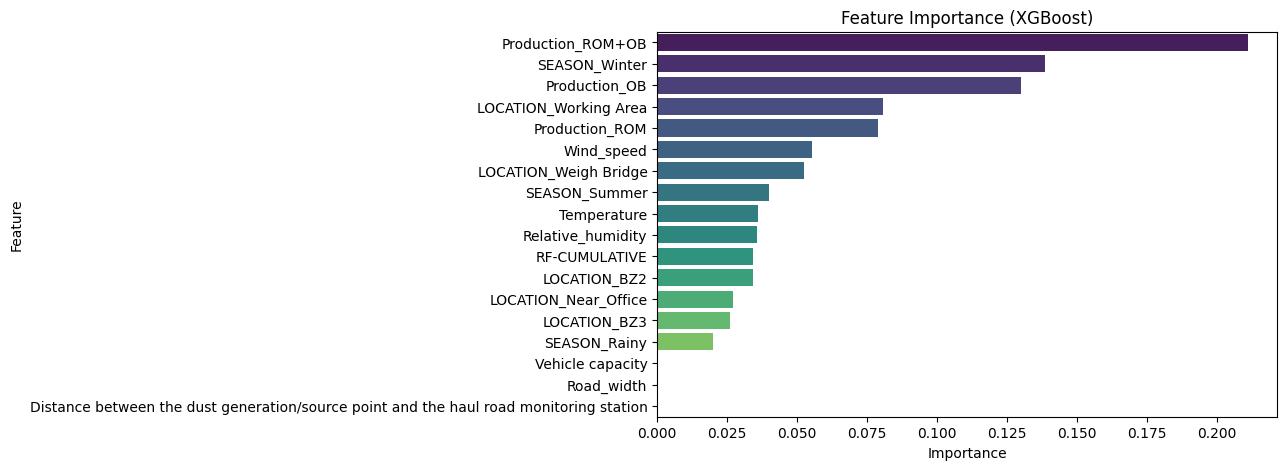

In [18]:
plt.figure(figsize=(8,5))

sns.barplot(
    data=importance,
    x="Importance",
    y="Feature",
    palette="viridis"
)

plt.title("Feature Importance (XGBoost)")

plt.show()

c:\Machine Learning\model_training\venv\Lib\site-packages\shap\plots\_beeswarm.py:1150: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


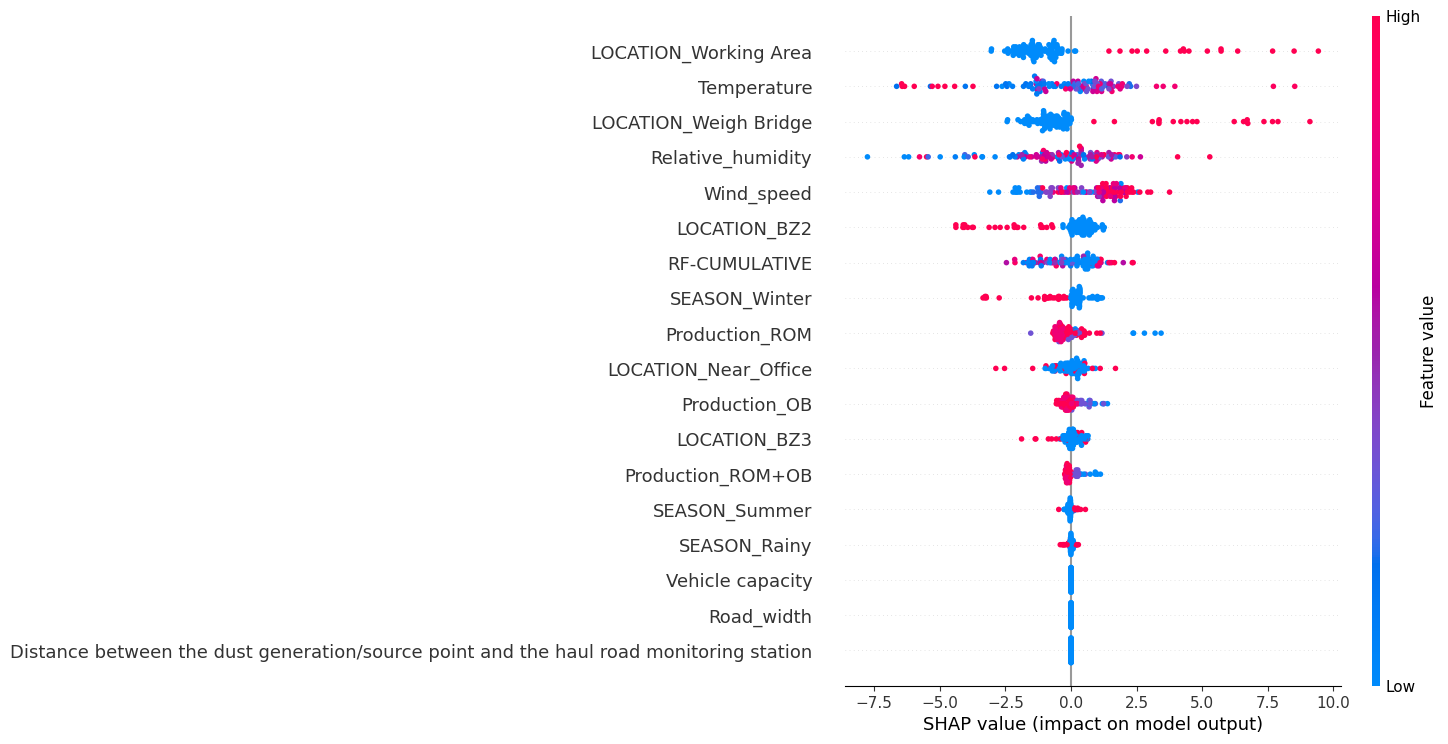

In [19]:
explainer = shap.TreeExplainer(xgb_model)

shap_values = explainer.shap_values(X_test)

shap.summary_plot(
    shap_values,
    X_test
)